# GameTheory-04i — Utilité espérée et aversion au risque

Le carnet [GameTheory-04-NashEquilibrium-Python.ipynb](GameTheory-04-NashEquilibrium-Python.ipynb) calcule des équilibres de Nash en stratégies mixtes sur des matrices de paiements **numériques**. Mais d'où viennent ces nombres ? La condition d'indifférence qui détermine un équilibre mixte — « le gain espéré de chaque action jouée est égal » — compare des **espérances de nombres**, pas des classements : elle suppose que les paiements sont des **utilités cardinales**, construites depuis des préférences sur des loteries. Ce carnet construit ce chaînon manquant : le théorème de représentation de von Neumann-Morgenstern (vNM), l'élicitation d'une utilité normalisée, l'équivalence certaine et la prime de risque, puis — c'est sa contribution propre — il **mesure ce que l'aversion au risque fait aux équilibres des jeux mêmes du palier 04** (Dilemme du Prisonnier, Stag Hunt, Battle of the Sexes, Matching Pennies).

**Position dans la série** : accretion du palier 04 (les équilibres mixtes deviennent des équilibres *en utilités* ; le carnet [GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb](GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb) couvre l'autre lecture des mixtes, comme croyances, et non comme utilités). Source principale : Bonanno (2015), ch. 4 « Expected Utility » — lu intégralement sur la copie archivée du gisement (`G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`).

## Références

**Bonanno (2015)**, *Game Theory*, ch. 4 « Expected Utility » (§4.1 attitudes face au risque, Théorèmes 4.1-4.2, §4.3 axiomes) : la colonne vertébrale de ce carnet, y compris l'exercice 4.11 (deux individus averses au risque qui classent différemment deux loteries) reproduit ci-dessous avec des fonctions mesurées. **von Neumann & Morgenstern (1944)** : le théorème de représentation original. Gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`. Les jeux mesurés en section 6 sont ceux du palier 04.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nashpy as nash
from fractions import Fraction

print("numpy", np.__version__, "| nashpy", nash.__version__)

numpy 2.2.6 | nashpy 0.0.43


## 1. Loteries d'argent et attitudes face au risque

Une **loterie d'argent** est une distribution de probabilité sur des montants : $L = \left(\$x_1, \dots, \$x_n;\ p_1, \dots, p_n\right)$. Sa valeur espérée est $\mathbb{E}[L] = \sum_i p_i x_i$. Bonanno (§4.1) classe les attitudes face au risque **par rapport à la valeur espérée** (Définition 4.1) : un individu est **averse au risque** s'il préfère (ou est indifférent à) recevoir $\mathbb{E}[L]$ avec certitude plutôt que de jouer $L$ ; **risque-neutre** s'il est indifférent ; **risque-aimant** dans le cas contraire.

In [2]:
class Loterie:
    """Loterie d'argent : montants > 0 et probabilites (somme = 1)."""

    def __init__(self, montants, probs):
        self.montants = np.array(montants, dtype=float)
        self.probs = np.array(probs, dtype=float)
        assert abs(self.probs.sum() - 1.0) < 1e-12, "les probabilites doivent sommer a 1"

    def esperance(self):
        return float(self.probs @ self.montants)

    def utilite_esperee(self, U):
        return float(self.probs @ U(self.montants))

    def affiche(self, nom):
        parts = ", ".join(f"${m:.0f} @ {p:.4g}" for m, p in zip(self.montants, self.probs))
        print(f"{nom} = ({parts})   E[{nom}] = ${self.esperance():.2f}")

# Les deux loteries du chapitre (Bonanno, section 4.1)
L1 = Loterie([30, 45, 90], [1/3, 5/9, 1/9])   # E[L1] = 45 (probabilites de la source)
L2 = Loterie([5, 100], [3/5, 2/5])
L1.affiche("L1")
L2.affiche("L2")

# Un individu risque-neutre classe L1 > L2 par simple transitivite :
print(f"risque-neutre : $45 sur  -> L1 ; $43 sur  -> L2 ; or 45 > 43, donc L1 > L2")

L1 = ($30 @ 0.3333, $45 @ 0.5556, $90 @ 0.1111)   E[L1] = $45.00
L2 = ($5 @ 0.6, $100 @ 0.4)   E[L2] = $43.00
risque-neutre : $45 sur  -> L1 ; $43 sur  -> L2 ; or 45 > 43, donc L1 > L2


### Le classement de deux loteries arbitraires ne suit pas de l'attitude face au risque

Connaître l'attitude d'un individu (déf. 4.1) ne **suffit pas** à prédire comment il classe deux loteries arbitraires. Le contre-exemple du chapitre (exercice 4.11) : $L_3 = \$28$ certain et $L_4 = (\$10, \$50;\ \tfrac{1}{2}, \tfrac{1}{2})$ avec $\mathbb{E}[L_4] = \$30 > \$28$. **Ann** a l'utilité $U_{Ann}(m) = \sqrt{m}$ ; **Bob** l'utilité concave $U_{Bob}(m) = m - m^2/1000$ (construite sur le modèle de l'exercice). Vérifions les trois faits : chacun est averse au risque au sens de la définition, et pourtant leurs classements s'opposent.

In [3]:
L3 = Loterie([28], [1.0])
L4 = Loterie([10, 50], [0.5, 0.5])

U_ann = np.sqrt
U_bob = lambda m: m - m**2 / 1000.0

for nom, U in [("Ann (sqrt)", U_ann), ("Bob (m - m^2/1000)", U_bob)]:
    eu3 = L3.utilite_esperee(U)
    eu4 = L4.utilite_esperee(U)
    u_e4 = U(30.0)  # utilite de la valeur esperee de L4, recue avec certitude
    pref = "L3 > L4" if eu3 > eu4 else "L4 > L3"
    attitude = "averse" if u_e4 > eu4 else ("neutre" if abs(u_e4 - eu4) < 1e-12 else "aimant")
    print(f"{nom:24s} EU(L3) = {eu3:.4f} | EU(L4) = {eu4:.4f} | U(E[L4]=$30) = {u_e4:.4f}")
    print(f"{'':24s} classement : {pref}  |  attitude face a L4 vs $30 : {attitude}")

Ann (sqrt)               EU(L3) = 5.2915 | EU(L4) = 5.1167 | U(E[L4]=$30) = 5.4772
                         classement : L3 > L4  |  attitude face a L4 vs $30 : averse
Bob (m - m^2/1000)       EU(L3) = 27.2160 | EU(L4) = 28.7000 | U(E[L4]=$30) = 29.1000
                         classement : L4 > L3  |  attitude face a L4 vs $30 : averse


### Interprétation : deux averses au risque, deux classements

Ann préfère $L_3$ : la racine carrée pénalise assez le gain espéré supplémentaire ($30 contre $28) pour préférer la certitude. Bob préfère $L_4$ : sa concavité est faible, l'écart d'espérance ($2) domine. **Tous deux sont averses au risque** — chacun préfère $30 certains à $L_4$ — et pourtant ils classent $L_3$ et $L_4$ en sens opposés. La définition 4.1 qualifie une attitude *localement* (face à la valeur espérée) ; le classement *global* des loteries exige une fonction d'utilité complète : c'est l'objet du théorème de représentation.

## 2. Le théorème de représentation de von Neumann-Morgenstern

**Théorème 4.1 (Bonanno, ch. 4).** Si les préférences $\succsim$ sur les loteries satisfont quatre axiomes (section 4 ci-dessous), il existe une fonction $U$ sur les résultats de base telle que, pour toutes loteries $L, L'$ :

$$L \succ L' \iff \mathbb{E}[U(L)] > \mathbb{E}[U(L')]$$

**Théorème 4.2.** $U$ est unique **à transformation affine positive près** : si $U$ représente $\succsim$, alors $V = aU + b$ ($a > 0$) aussi, et toute autre représentation est de cette forme. C'est ce qui rend l'utilité **cardinale** : les *différences* d'utilité ont un sens (à un facteur d'échelle près), contrairement à l'utilité ordinale du ch. 1 — et c'est exactement ce dont la condition d'indifférence d'un équilibre mixte a besoin.

Une conséquence immédiate et puissante (l'exemple « Susan » du chapitre) : si Susan préfère $A = (o_2, o_3;\ 0.25, 0.75)$ à $B = (o_1, o_3;\ 0.2, 0.8)$, alors on peut **prédire** sans connaître $U$ qu'elle préfère $D = o_2$ certain à $C = (o_1, o_3;\ 0.8, 0.2)$ — car $\mathbb{E}[U(A)] > \mathbb{E}[U(B)]$ se réécrit $U(o_2) > 0.8\,U(o_1) + 0.2\,U(o_3)$. Mesurons la robustesse de cette prédiction à l'échelle affine.

In [4]:
def invariance_affine(U, a, b, loteries):
    """Classe un ensemble de loteries sous U puis sous V = a*U + b ; compare."""
    classe_U = sorted(loteries, key=lambda L: -L.utilite_esperee(U))
    classe_V = sorted(loteries, key=lambda L: -(a * L.utilite_esperee(U) + b))
    return classe_U == classe_V

# Loteries sur l'echelle de paiements du palier 04 (Battle of the Sexes : 0, 2, 3)
LA = Loterie([3, 2], [0.5, 0.5])      # la moitie Opera, la moitie Football
LB = Loterie([3], [1.0])              # Opera certain
LC = Loterie([2, 3], [0.7, 0.3])      # melange defavorable
loteries, noms = [LA, LB, LC], ["LA", "LB", "LC"]

for nom, U in [("U = sqrt", np.sqrt)]:
    classement = sorted(zip(noms, loteries), key=lambda t: -t[1].utilite_esperee(U))
    print(nom, "classement :", " > ".join(n for n, _ in classement))

for a, b, etiquette in [(3.0, 2.0, "V = 3U + 2   (a > 0)"), (0.1, -5.0, "V = 0.1U - 5 (a > 0)"), (-1.0, 7.0, "V = -U + 7  (a < 0)")]:
    conserve = invariance_affine(np.sqrt, a, b, loteries)
    print(f"{etiquette} : classement conserve = {conserve}")

# La prediction de type "Susan" : EU(A) > EU(B) implique U(o2) > 0.8 U(o1) + 0.2 U(o2)
def prediction_susan(u1, u2, u3):
    """A = .25 o2 + .75 o3 > B = .2 o1 + .8 o3  equivaut a  o2 > C = .8 o1 + .2 o2."""
    euA, euB = 0.25 * u2 + 0.75 * u3, 0.2 * u1 + 0.8 * u3
    euD, euC = u2, 0.8 * u1 + 0.2 * u3
    return (euA > euB) == (euD > euC)

import random
random.seed(7)
tests = [prediction_susan(random.uniform(0, 10), random.uniform(0, 10), random.uniform(0, 10)) for _ in range(10000)]
print(f"equivalence A>B <=> D>C verifiee sur 10000 triplets (u1,u2,u3) aleatoires : {all(tests)}")

U = sqrt classement : LB > LA > LC
V = 3U + 2   (a > 0) : classement conserve = True
V = 0.1U - 5 (a > 0) : classement conserve = True
V = -U + 7  (a < 0) : classement conserve = False


equivalence A>B <=> D>C verifiee sur 10000 triplets (u1,u2,u3) aleatoires : True


### Interprétation : l'échelle est arbitraire, l'ordre ne l'est pas

Toute transformation affine **positive** de $U$ conserve le classement des loteries ; une transformation **négative** le renverse. L'utilité vNM est donc une échelle de température : le zéro et l'unité sont conventionnels, mais les rapports de différences — $\frac{U(x)-U(y)}{U(z)-U(w)}$ — sont invariants. C'est pourquoi l'on peut **normaliser** $U$ sans perte (section suivante), et pourquoi un équilibre mixte — qui égalise des différences d'espérances — a un sens que la seule information ordinale ne peut pas porter.

## 3. Utilité normalisée et élicitation par équivalence de probabilité

**Définition 4.3 (normalisation).** Fixons $U(o_{best}) = 1$ et $U(o_{worst}) = 0$ — licite par le théorème 4.2. Alors pour tout résultat $o$, l'axiome de continuité garantit l'existence d'un $p$ tel que $o \sim (o_{best}, o_{worst};\ p, 1-p)$, et la normalisation donne exactement $U(o) = p$. **Éliciter** l'utilité d'un individu revient donc à lui poser des questions d'indifférence : « pour quelle probabilité $p$ êtes-vous indifférent entre $o$ et un tirage qui donne $o_{best}$ avec proba $p$, $o_{worst}$ sinon ? ». Avec $m$ résultats, $m-2$ questions suffisent (les deux extrêmes sont fixés par convention).

In [5]:
def elicite(indifferences, best, worst):
    """Construit l'utilite normalisee depuis des indifferences o ~ (best, worst; p, 1-p).

    indifferences : dict {o: p}. U(best)=1, U(worst)=0, U(o)=p pour chaque entree.
    Renvoie la fonction U sur les resultats declares + un controle de coherence.
    """
    table = {best: 1.0, worst: 0.0}
    table.update(indifferences)
    def U(o):
        if o in table:
            return table[o]
        raise KeyError(f"resultat non elicite : {o}")
    return U, table

# Exemple : cinq destinations de week-end, preferences globales o2 > o1 ~ o5 > o3 ~ o4
# Reponses de l'individu (modele de l'Example 4.1 du chapitre) :
#   o1 indifferent a (o2 @ 0.4, o3 @ 0.6)  ->  U(o1) = 0.4
#   o5 indifferent a o1                     ->  U(o5) = U(o1)
U, table = elicite({"o1": 0.4, "o5": 0.4}, best="o2", worst="o3")
for o in ["o1", "o2", "o3", "o4", "o5"]:
    print(f"U({o}) = {U(o):.2f}" if o in table and o != "o4" else f"U({o}) = 0.00   (indifferent a o3, le pire)")

# Controle independant : la preference declaree o1 > o3 doit se relire dans la table
assert U("o1") > U("o3"), "incoherence : o1 devrait dominer o3"
print("controle : U(o1) > U(o3) verifie, la table est coherente avec le classement declare")

U(o1) = 0.40
U(o2) = 1.00
U(o3) = 0.00
U(o4) = 0.00   (indifferent a o3, le pire)
U(o5) = 0.40
controle : U(o1) > U(o3) verifie, la table est coherente avec le classement declare


### Interprétation : la probabilité d'indifférence EST l'utilité

Une fois les extrêmes normalisés à 1 et 0, chaque réponse d'indifférence fournit directement une valeur d'utilité : ici $U = (0.4,\ 1,\ 0,\ 0,\ 0.4)$ sur $(o_1, o_2, o_3, o_4, o_5)$. Trois questions ont suffi pour cinq résultats. Ce protocole — dit d'**équivalence de probabilité** — est celui qu'utilisent l'économie expérimentale et la théorie de la décision pour mesurer l'utilité d'un individu ; la section 5 l'applique à des montants en euros.

## 4. Les quatre axiomes et la réduction des loteries composées

Le théorème 4.1 repose sur quatre axiomes (Bonanno, §4.3) : **(1)** complétude et transitivité des préférences sur les loteries ; **(2)** monotonicité (plus d'argent est préféré) ; **(3)** continuité (pas de saut infinitésimal : l'indifférence $o \sim (o_{best}, o_{worst}; p, 1-p)$ existe) ; **(4)** indépendance (substituabilité) : si $L \sim L'$, alors remplacer $L$ par $L'$ **au sein d'une loterie composée** ne change pas les préférences. L'axiome 4 a une conséquence calculable : une loterie composée (un tirage dont les prix sont eux-mêmes des loteries) est équivalente à la **loterie simple** obtenue en multipliant les probabilités le long des branches de l'arbre — exactement la mécanique de la Figure 4.2 du chapitre.

In [6]:
# Loterie composee construite sur le modele de la Figure 4.1 du chapitre :
#   C = 1/3 * [ o1 @ 1/2 ; 1/2 * [ o3 @ 1/3 ; 2/3 * [ o2 @ 1/2 ; o4 @ 1/2 ] ] ]
#          + 2/3 * [ o1 @ 1/4 ; o2 @ 0  ; 3/4 * [ o3 @ 1/5 ; o4 @ 4/5 ] ]
branches = [
    (Fraction(1, 3), [("o1", Fraction(1, 2)),
                      ("loterie", Fraction(1, 2), [("o3", Fraction(1, 3)),
                                                   ("loterie", Fraction(2, 3), [("o2", Fraction(1, 2)),
                                                                                ("o4", Fraction(1, 2))])])]),
    (Fraction(2, 3), [("o1", Fraction(1, 4)),
                      ("o2", Fraction(0, 1)),
                      ("loterie", Fraction(3, 4), [("o3", Fraction(1, 5)),
                                                   ("o4", Fraction(4, 5))])]),
]

def reduit(poids, noeud, acc):
    """Multiplie les probabilites le long des branches et accumule par resultat (exact)."""
    for feuille in noeud:
        nom = feuille[0]
        if nom == "loterie":
            reduit(poids * feuille[1], feuille[2], acc)
        else:
            acc[nom] = acc.get(nom, Fraction(0)) + poids * feuille[1]

probas = {}
for poids, noeud in branches:
    reduit(poids, noeud, probas)

print("Loteries simples equivalentes (fractions exactes) :")
total = Fraction(0)
for o in sorted(probas):
    print(f"  P({o}) = {probas[o]} = {float(probas[o]):.6f}")
    total += probas[o]
print(f"  somme  = {total} (doit valoir 1)")
assert total == 1

# Les branches de la premiere ligne : P(o1) = 1/3*1/2 + 2/3*1/4 = 1/6 + 1/6
print(f"controle P(o1) : 1/3*1/2 + 2/3*1/4 = {Fraction(1,3)*Fraction(1,2) + Fraction(2,3)*Fraction(1,4)}")

Loteries simples equivalentes (fractions exactes) :
  P(o1) = 1/3 = 0.333333
  P(o2) = 1/18 = 0.055556
  P(o3) = 7/45 = 0.155556
  P(o4) = 41/90 = 0.455556
  somme  = 1 (doit valoir 1)
controle P(o1) : 1/3*1/2 + 2/3*1/4 = 1/3


### Interprétation : l'axiome d'indépendance fait le calcul

La loterie composée se réduit exactement — en fractions rationnelles, sans aucune approximation — en multipliant les probabilités le long de chaque chemin de l'arbre puis en sommant par résultat, et la somme vaut exactement 1. C'est l'axiome d'indépendance qui **autorise** cette réduction : traiter une loterie comme un prix substituable dans une loterie plus grande. C'est aussi l'axiome le plus discuté de la théorie (paradoxe d'Allais) — mais sans lui, l'équivalence « composer = réduire » disparaît, et avec elle l'interprétation des stratégies mixtes comme tirages uniques.

## 5. Équivalence certaine et prime de risque

Une fois $U$ connue, chaque loterie $L$ a un **équivalent certain** $CE(L) = U^{-1}(\mathbb{E}[U(L)])$ : le montant certain qui laisse l'individu exactement aussi satisfait que la loterie. Pour un individu averse au risque ($U$ concave, donc croissante), la concavité (inégalité de Jensen) donne $CE(L) \le \mathbb{E}[L]$ ; l'écart $\pi(L) = \mathbb{E}[L] - CE(L) \ge 0$ est la **prime de risque** — le montant que l'individu est prêt à payer pour éliminer le risque. La définition 4.1 du section 1 se relit alors : averse au risque $\iff$ prime de risque (faiblement) positive sur toute loterie.

L_mix = ($3 @ 0.24, $2 @ 0.24, $0 @ 0.52)   E[L_mix] = $1.20
gain espere en euros      E[L_mix] = $1.200  (le carnet 04 affiche 1.2)
equivalent certain (sqrt)  CE      = $0.570   prime de risque = $0.630
equivalent certain (log)   CE      = $0.816   prime de risque = $0.384


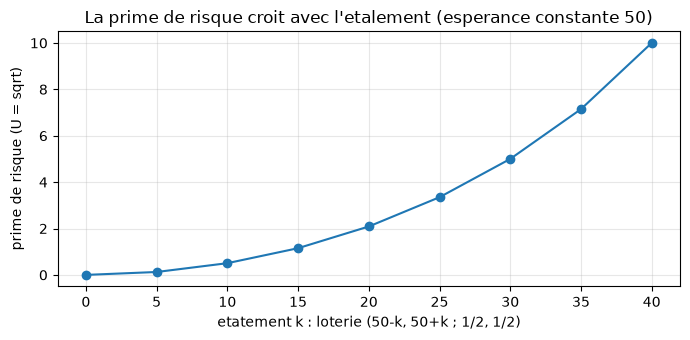

prime k=0 : -0.0000 | k=20 : 2.087 | k=40 : 10.000


In [7]:
def equivalent_certain(L, U, U_inv):
    return float(U_inv(L.utilite_esperee(U)))

# Application : les paiements du Battle of the Sexes du palier 04 (A = [[3,0],[0,2]])
# L'equilibre mixte neutre (p,q) = (0.6, 0.4) fait de la PAYOFF de Row une loterie :
#   3 @ p*q (Opera-Opera),  2 @ (1-p)(1-q) (Football-Football),  0 sinon
p, q = 0.6, 0.4
L_eq_bos = Loterie([3, 2, 0], [p * q, (1 - p) * (1 - q), 1 - p * q - (1 - p) * (1 - q)])
L_eq_bos.affiche("L_mix")

CE_sqrt = equivalent_certain(L_eq_bos, np.sqrt, lambda u: u**2)
CE_ln = equivalent_certain(L_eq_bos, lambda m: np.log(m + 1.0), lambda u: np.exp(u) - 1.0)
E = L_eq_bos.esperance()

print(f"gain espere en euros      E[L_mix] = ${E:.3f}  (le carnet 04 affiche 1.2)")
print(f"equivalent certain (sqrt)  CE      = ${CE_sqrt:.3f}   prime de risque = ${E - CE_sqrt:.3f}")
print(f"equivalent certain (log)   CE      = ${CE_ln:.3f}   prime de risque = ${E - CE_ln:.3f}")

# Courbe : prime de risque de la loterie (50-k, 50+k ; 1/2, 1/2) en fonction de l'etalement k
ks = np.linspace(0, 40, 9)
primes = []
for k in ks:
    Lk = Loterie([50 - k, 50 + k], [0.5, 0.5])
    primes.append(Lk.esperance() - equivalent_certain(Lk, np.sqrt, lambda u: u**2))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ks, primes, "o-")
ax.set_xlabel("etatement k : loterie (50-k, 50+k ; 1/2, 1/2)")
ax.set_ylabel("prime de risque (U = sqrt)")
ax.set_title("La prime de risque croit avec l'etalement (esperance constante 50)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"prime k=0 : {primes[0]:.4f} | k=20 : {primes[4]:.3f} | k=40 : {primes[8]:.3f}")

### Interprétation : le risque se paie, et se paie de plus en plus

La loterie de paiement de l'équilibre mixte du Battle of the Sexes a une espérance de $1.2 (le gain que le carnet 04 affiche) ; un joueur d'utilité $\sqrt{m}$ n'y accorde que l'équivalent certain calculé ci-dessus — la différence est le prix qu'il accorde au risque de méscoordination (52 % des tirages tombent sur un rendez-vous manqué). Sur la famille à espérance constante 50, la prime de risque croît avec l'étalement $k$ : à espérance égale, **plus le risque est dispersé, plus il coûte cher** à un individu aversé. La section suivante montre que ce prix n'est pas un simple confort psychologique : il **déplace les équilibres** des jeux du palier 04.

## 6. Le pont vers le palier 04 : l'aversion au risque déplace les équilibres mixtes

Les matrices du carnet 04 — Dilemme du Prisonnier $\begin{pmatrix}3&0\\5&1\end{pmatrix}$, Stag Hunt $\begin{pmatrix}4&0\\3&3\end{pmatrix}$, Battle of the Sexes $\begin{pmatrix}3&0\\0&2\end{pmatrix}$ (et sa transpose pour Col) — sont des **utilités**. Si leurs paiements se lisent en euros, un joueur aversé au risque ne joue pas ce jeu-là : il joue le jeu transformé $U(A), U(B)$. Or la théorie prédit deux destins très différents : les **équilibres purs** ne dépendent que de l'ordre des paiements (meilleures réponses), donc survivent à toute transformation croissante ; les **équilibres mixtes** égalisent des différences d'espérances — des grandeurs cardinales — donc **bougent** avec la courbure de $U$. Mesurons les trois jeux, avec les utilités neutre $U(m) = m$, averse $U(m) = \sqrt{m}$ et risque-aimant $U(m) = m^{1.5}$.

In [8]:
A_pd = np.array([[3.0, 0.0], [5.0, 1.0]])
B_pd = np.array([[3.0, 5.0], [0.0, 1.0]])

def equilibres(A, B):
    jeu = nash.Game(A, B)
    resultats = []
    for eq in jeu.support_enumeration():
        sr, sc = np.round(eq[0], 6), np.round(eq[1], 6)
        resultats.append((sr, sc))
    return resultats

print("Dilemme du Prisonnier du palier 04 sous trois utilites")
print("=" * 60)
for nom, U in [("neutre  U=m", lambda m: m), ("averse  U=sqrt(m)", np.sqrt), ("aimant  U=m^1.5", lambda m: m**1.5)]:
    Ap, Bp = U(A_pd), U(B_pd)
    dom = "Defaire domine Cooperer" if (Ap[1, 0] > Ap[0, 0] and Ap[1, 1] > Ap[0, 1]) else "domination brisee !"
    eqs = equilibres(Ap, Bp)
    print(f"{nom:18s} | {dom} | equilibres nashpy : {len(eqs)} -> (Defaire, Defaire) present : "
          f"{any(abs(e[0][1] - 1) < 1e-9 and abs(e[1][1] - 1) < 1e-9 for e in eqs)}")

Dilemme du Prisonnier du palier 04 sous trois utilites
neutre  U=m        | Defaire domine Cooperer | equilibres nashpy : 1 -> (Defaire, Defaire) present : True
averse  U=sqrt(m)  | Defaire domine Cooperer | equilibres nashpy : 1 -> (Defaire, Defaire) present : True
aimant  U=m^1.5    | Defaire domine Cooperer | equilibres nashpy : 1 -> (Defaire, Defaire) present : True


### Interprétation : les équilibres purs sont ordinalement robustes

Le Dilemme du Prisonnier garde son unique équilibre $(Defaire, Defaire)$ sous les trois utilités : une transformation strictement croissante ne peut pas inverser une domination stricte. Plus généralement, tout équilibre pur ne dépend que des **meilleures réponses** — une information ordinale. Un résultat du palier 04 portant sur les équilibres purs survit donc à n'importe quelle relecture des paiements en euros ; c'est une robustesse **mesurable**, pas une intuition.

In [9]:
A_bos = np.array([[3.0, 0.0], [0.0, 2.0]])   # Row : Opera/Football
B_bos = np.array([[2.0, 0.0], [0.0, 3.0]])   # Col : Opera/Football

def mixte_interieur(A, B):
    """Equilibre mixte interieur d'un jeu 2x2 par indifference (formule du carnet 04)."""
    q = (A[1, 1] - A[0, 1]) / (A[0, 0] - A[0, 1] - A[1, 0] + A[1, 1])  # Col joue action 0
    p = (B[1, 1] - B[1, 0]) / (B[0, 0] - B[1, 0] - B[0, 1] + B[1, 1])  # Row joue action 0
    return p, q

print("Battle of the Sexes (palier 04 : A = [[3,0],[0,2]], B = [[2,0],[0,3]])")
print("=" * 60)
print(f"{'utilite':18s} | {'p* (Row=Opera)':>14s} | {'q* (Col=Opera)':>14s} | verif nashpy")
for nom, U in [("neutre  U=m", lambda m: m), ("averse  U=sqrt(m)", np.sqrt), ("aimant  U=m^1.5", lambda m: m**1.5)]:
    Ap, Bp = U(A_bos), U(B_bos)
    p, q = mixte_interieur(Ap, Bp)
    eqs = equilibres(Ap, Bp)
    mixte = [e for e in eqs if 1e-6 < e[0][0] < 1 - 1e-6]
    p_n, q_n = (mixte[0][0][0], mixte[0][1][0]) if mixte else (float("nan"),) * 2
    print(f"{nom:18s} | {p:14.4f} | {q:14.4f} | ({p_n:.4f}, {q_n:.4f})")

p_n, p_a = mixte_interieur(A_bos, B_bos)[0], mixte_interieur(np.sqrt(A_bos), np.sqrt(B_bos))[0]
print(f"\ndeplacement de p* sous aversion (sqrt) : {p_n:.3f} -> {p_a:.3f} "
      f"(soit {abs(p_a - p_n)/p_n*100:.1f}% de baisse, vers 50/50)")

Battle of the Sexes (palier 04 : A = [[3,0],[0,2]], B = [[2,0],[0,3]])
utilite            | p* (Row=Opera) | q* (Col=Opera) | verif nashpy
neutre  U=m        |         0.6000 |         0.4000 | (0.6000, 0.4000)
averse  U=sqrt(m)  |         0.5505 |         0.4495 | (0.5505, 0.4495)
aimant  U=m^1.5    |         0.6475 |         0.3525 | (0.6475, 0.3525)

deplacement de p* sous aversion (sqrt) : 0.600 -> 0.551 (soit 8.2% de baisse, vers 50/50)


### Interprétation : l'équilibre mixte migre vers 50/50

Le résultat central du carnet : sous utilité neutre, l'équilibre mixte du Battle of the Sexes est $(p^*, q^*) = (0.6, 0.4)$ — le carnet 04 affiche exactement ces valeurs ; sous $\sqrt{m}$ les deux probabilités migrent **vers ½**, et sous utilité convexe elles s'en éloignent. La raison est structurelle : $q^*$ égalise $3q$ et $2(1-q)$ pour Row ; la transformation comprime l'écart $3$ vs $2$ en $\sqrt{3}$ vs $\sqrt{2}$ — un écart plus faible, donc un point d'indifférence plus proche de la symétrie. **La condition d'indifférence d'un équilibre mixte est une égalité de différences cardinales** : changer la courbure de l'utilité change l'équilibre, quand les équilibres purs (Opera-Opera, Football-Football) restent intacts. Les probabilités mixtes du palier 04 ne sont donc pas des propriétés du jeu « en euros » : ce sont des propriétés conjointes du jeu **et** de l'attitude face au risque des joueurs.

Stag Hunt (palier 04 : A = [[4,0],[3,3]], B = [[4,3],[0,3]])
neutre  U=m        | seuil p* (proba Stag de l'adversaire rendant indifferent) = 0.7500
averse  U=sqrt(m)  | seuil p* (proba Stag de l'adversaire rendant indifferent) = 0.8660


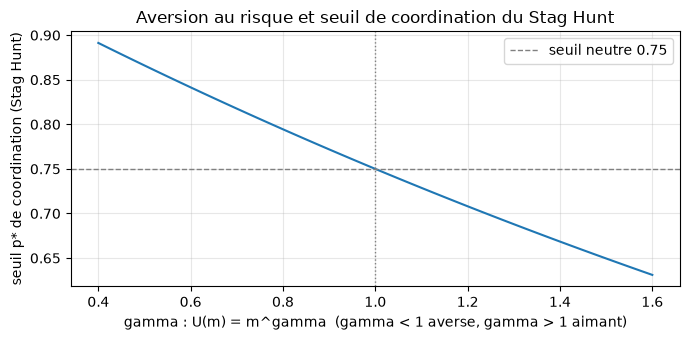

gamma=0.4 (tres averse) seuil = 0.8913 | gamma=1.4 (aimant) seuil = 0.6311


In [10]:
A_stag = np.array([[4.0, 0.0], [3.0, 3.0]])
B_stag = np.array([[4.0, 3.0], [0.0, 3.0]])

print("Stag Hunt (palier 04 : A = [[4,0],[3,3]], B = [[4,3],[0,3]])")
print("=" * 60)
for nom, U in [("neutre  U=m", lambda m: m), ("averse  U=sqrt(m)", np.sqrt)]:
    p, q = mixte_interieur(U(A_stag), U(B_stag))
    print(f"{nom:18s} | seuil p* (proba Stag de l'adversaire rendant indifferent) = {p:.4f}")

# Courbe complete : seuil en fonction du coefficient d'aversion gamma (U = m^gamma, gamma < 1 averse)
gammas = np.linspace(0.4, 1.6, 49)
seuils = [mixte_interieur(A_stag**g if g != 1.0 else A_stag, B_stag**g if g != 1.0 else B_stag)[0] for g in gammas]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(gammas, seuils)
ax.axhline(0.75, color="gray", ls="--", lw=1, label="seuil neutre 0.75")
ax.axvline(1.0, color="gray", ls=":", lw=1)
ax.set_xlabel("gamma : U(m) = m^gamma  (gamma < 1 averse, gamma > 1 aimant)")
ax.set_ylabel("seuil p* de coordination (Stag Hunt)")
ax.set_title("Aversion au risque et seuil de coordination du Stag Hunt")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
i_av, i_ai = 10, 44
print(f"gamma=0.4 (tres averse) seuil = {seuils[0]:.4f} | gamma=1.4 (aimant) seuil = {seuils[-1]:.4f}")

### Interprétation : l'aversion au risque durcit la coordination

Le seuil de coordination du Stag Hunt monte de $0.75$ (neutre) à $0.866$ sous $\sqrt{m}$ : il faut désormais une croyance plus élevée que l'autre chasse le cerf pour oser le chasser soi-même. La courbe en fonction de $\gamma$ est monotone : plus les joueurs sont averses au risque, plus le « bon » équilibre (chasse collective au cerf, gain 4) exige de confiance mutuelle — et un groupe d'individus averses se coordonne plus difficilement sur lui, alors même que cet équilibre est préféré par tous. **L'aversion au risque est un paramètre du jeu**, au même titre que les paiements eux-mêmes : la relire depuis les euros modifie les prédictions du palier 04 sur les équilibres mixtes, pas sur les équilibres purs.

### Matching Pennies : le cas qui ne bouge pas

Le Matching Pennies du palier 04, $\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$ à somme nulle, garde son équilibre $(\tfrac{1}{2}, \tfrac{1}{2})$ sous toute transformation croissante **symétrique** des paiements : la symétrie du jeu, pas la cardinalité, fixe l'équilibre. C'est le contrepoint utile des deux sections précédentes — le déplacement des équilibres mixtes par l'utilité est réel mais n'est pas universel : il apparaît quand les paiements des joueurs ne sont pas liés par une symétrie qui écrase l'effet de courbure. Les matrices du palier 04 sont donc à lire comme des **utilités** ; les convertir depuis des euros (ou non) est un choix de modélisation qui change les prédictions mixtes, et ce carnet fournit l'outillage (élicitation, section 3) pour le faire proprement.

## 7. Exercices

Trois exercices pour s'approprier le pont loteries-jeux. Les stubs s'exécutent sans erreur ; complétez les corps des fonctions (les `TODO` indiquent l'attendu, les indices la méthode).

### Exercice 1 : élicitation sur six résultats

Six montants $m_1 > m_2 > \dots > m_6$. Élicitez l'utilité normalisée par quatre questions d'indifférence ($m_2, m_3, m_4, m_5$), puis vérifiez la cohérence : $U(m_3)$ doit rester strictement entre $U(m_2)$ et $U(m_4)$. Indice : $U(m_1) = 1$, $U(m_6) = 0$, et chaque réponse d'indifférence $m_i \sim (m_1, m_6; p_i, 1-p_i)$ donne directement $U(m_i) = p_i$.

In [11]:
def exercice_1_elicitation_six_resultats(reponses: dict) -> dict:
    """reponses : {mi: pi} pour i = 2..5, issues des questions d'indifference."""
    pass  # TODO etudiant : retourner la table complete {m1: 1.0, m2: ..., ..., m6: 0.0}
    return None

# Controle attendu : pour reponses = {m2: 0.8, m3: 0.5, m4: 0.3, m5: 0.1},
#   la table doit decroitre strictement de 1.0 a 0.0.
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 : prime de risque croissante sous utilité logarithmique

Construisez les loteries $(50-k, 50+k; \tfrac{1}{2}, \tfrac{1}{2})$ pour $k = 0, 5, \dots, 40$ sous $U(m) = \log(1+m)$, calculez les primes de risque et vérifiez qu'elles croissent avec $k$. Indice : $CE = U^{-1}(\mathbb{E}[U(L)])$ avec $U^{-1}(u) = e^u - 1$ ; prime $= 50 - CE$.

In [12]:
def exercice_2_prime_croissante_log() -> list:
    pass  # TODO etudiant : retourner la liste [(k, prime), ...] pour k = 0, 5, ..., 40
    return None

print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 : retransformer les jeux du palier 04

Appliquez $U(m) = \log(1+m)$ aux matrices du Dilemme du Prisonnier et du Stag Hunt du palier 04, recalculez les équilibres et comparez au cas neutre. Questions : (a) l'équilibre $(Defaire, Defaire)$ survit-il ? (b) le seuil de coordination du Stag Hunt monte-t-il, et de combien ? Indice : `np.log1p(A)` applique $\log(1+m)$ à toute la matrice ; la fonction `mixte_interieur(A, B)` est fournie en section 6.

In [13]:
def exercice_3_log_sur_palier04() -> dict:
    pass  # TODO etudiant : retourner {"pd_eq_survit": bool, "stag_seuil_neutre": float, "stag_seuil_log": float}
    return None

print("Exercice 3 a completer")

Exercice 3 a completer


## 8. Résumé

| Concept | Énoncé | Où il est mesuré |
|---|---|---|
| **Attitude face au risque** (déf. 4.1) | classe $L$ contre $\mathbb{E}[L]$ certain | section 1 — Ann et Bob averses, classements opposés |
| **Théorème vNM** (4.1-4.2) | $L \succ L' \iff \mathbb{E}[U(L)] > \mathbb{E}[U(L')]$, $U$ unique à affine positive près | section 2 — invariance testée sur 3 transformations + prédiction de type Susan |
| **Élicitation normalisée** | $U(o) = p$ où $o \sim (o_{best}, o_{worst}; p, 1-p)$ | section 3 — table $(0.4, 1, 0, 0, 0.4)$ en trois questions |
| **Réduction** (axiome 4) | loterie composée $\equiv$ loterie simple, probabilités multipliées le long de l'arbre | section 4 — fractions exactes, somme $= 1$ |
| **Équivalent certain / prime** | $CE = U^{-1}(\mathbb{E}[U(L)])$, $\pi = \mathbb{E}[L] - CE$ | section 5 — loterie d'équilibre du BoS, courbe en $k$ |
| **Robustesse ordinale** | les équilibres purs survivent à toute transformation croissante | section 6 — PD invariant sous 3 utilités |
| **Sensibilité cardinale** | les équilibres mixtes égalisent des différences : ils migrent avec $U$ | section 6 — BoS $0.6 \to 0.55$, Stag Hunt $0.75 \to 0.87$ |

**Le pont vers le palier 04** : les probabilités mixtes calculées dans le carnet 04 ne sont des prédictions sur un jeu d'argent qu'une fois choisie une attitude face au risque. Ce carnet fournit la chaîne complète : préférences $\to$ utilité élicitée $\to$ jeu transformé $\to$ équilibres recalculés — chaque maillon mesuré sur les matrices mêmes du palier.

## Références académiques

1. **von Neumann, J. & Morgenstern, O. (1944).** *Theory of Games and Economic Behavior.* Princeton University Press. — l'axiomatique originale de l'utilité espérée (démonstration que des préférences satisfaisant les axiomes admettent une représentation linéaire en probabilités, unique à transformation affine positive près).
2. **Bonanno, G. (2015).** *Game Theory* (open access textbook, 165 solved exercises), ch. 4 « Expected Utility ». arXiv:1512.06808. — la source directe de ce carnet : définition 4.1 (attitudes), théorèmes 4.1-4.2 (représentation, unicité affine), exemple d'élicitation, axiomes 1-4 et réduction, exercice 4.11 (deux averses au risque aux classements opposés). Copie archivée dans le gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\` ; licence CC BY-NC-ND 4.0 vérifiée page de copyright du PDF.
3. **Knight, V. & Campbell, J. (2018).** *Nashpy: A Python library for the computation of Nash equilibria.* Journal of Open Source Software 3(30): 904. doi:10.21105/joss.00904. — recalcule ici les équilibres des jeux transformés (section 6), indépendamment de la formule d'indifférence.
4. **Jensen, J. L. W. V. (1906).** *Sur les fonctions convexes et les inégalités entre les valeurs moyennes.* Acta Mathematica 30: 175-193. — l'inégalité de convexité qui fonde $CE(L) \le \mathbb{E}[L]$ pour toute utilité concave (prime de risque positive de l'averse).

> **Lien avec le palier 04** : les jeux mesurés en section 6 sont exactement ceux de [GameTheory-04-NashEquilibrium-Python.ipynb](GameTheory-04-NashEquilibrium-Python.ipynb) (ses sections 2 et 4). La lecture « croyances » des stratégies mixtes est traitée dans [GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb](GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb).

***